# **Invasive Lionfish and Native White Grunt Distribution**

## GEOG 592 — Cartography with Matplotlib

My project compares GBIF occurrence records for invasive red lionfish (Pterois volitans) & native white grunt (Haemulon plumierii). My goal is to explore their geographic distributions & identify areas of potential spatial overlap along the U.S. Atlantic and Gulf coasts.

In [3]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify
import time

Using Python's requests library, I accessed the GBIF API to check available observations for invasive lionfish (Pterois volitans) and native white grunt (Haemulon plumierii).

I filtered for U.S. human observations from 2015–2025 with geographic coordinates and no flagged geospatial issues. This helps determine whether both species have enough records for a meaningful comparison before downloading the data.

https://www.gbif.org/

In [4]:
species = ["Pterois volitans", "Haemulon plumierii"]

api = "https://api.gbif.org/v1"

for name in species:

    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()

    match = response.json()
    taxon_key = match.get("acceptedUsageKey", match.get("usageKey"))

    response = requests.get(
        f"{api}/occurrence/search",
        params={
            "taxonKey": taxon_key,
            "country": "US",
            "hasCoordinate": "true",
            "hasGeospatialIssue": "false",
            "basisOfRecord": "HUMAN_OBSERVATION",
            "occurrenceStatus": "PRESENT",
            "year": "2015,2025",
            "limit": 0
        },
        timeout=60
    )
    response.raise_for_status()

    print(name, ":", response.json()["count"], "records")

Pterois volitans : 456 records
Haemulon plumierii : 9398 records


Both species have GBIF records available, although white grunt has substantially more observations than lionfish. I will now retrieve their geographic coordinates and organize the records into a pandas DataFrame for mapping.

In [ ]:
records = []

for name in species:

    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60)
    response.raise_for_status()
    match = response.json()
    taxon_key = match.get("acceptedUsageKey", match.get("usageKey"))

    params = {
        "taxonKey": taxon_key,
        "country": "US",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "year": "2015,2025",
        "limit": 300,
        "offset": 0}

    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=params,
            timeout=60)
        response.raise_for_status()
        page = response.json()

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        params["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: downloaded {len(species_records)} records")

fish = pd.DataFrame(records)

fish = fish[
    ["queried_species", "decimalLongitude", "decimalLatitude"]
].dropna()

fish.head()

Pterois volitans: downloaded 456 records
Haemulon plumierii: downloaded 9398 records


,queried_species,decimalLongitude,decimalLatitude
0,Pterois volitans,-80.006321,26.714364
1,Pterois volitans,-80.050424,26.763571
2,Pterois volitans,-81.303709,29.951974
3,Pterois volitans,-80.044041,26.783053
4,Pterois volitans,-80.079036,26.952495


I converted the GBIF observation coordinates into a GeoDataFrame using GeoPandas. This allows me to map the locations of both species and examine their geographic distributions.

In [6]:
fish_points = gpd.GeoDataFrame(
    fish.copy(),
    geometry=gpd.points_from_xy(
        fish["decimalLongitude"],
        fish["decimalLatitude"]
    ),
    crs="EPSG:4326")

fish_points.head()

,queried_species,decimalLongitude,decimalLatitude,geometry
0,Pterois volitans,-80.006321,26.714364,POINT (-80.00632 26.71436)
1,Pterois volitans,-80.050424,26.763571,POINT (-80.05042 26.76357)
2,Pterois volitans,-81.303709,29.951974,POINT (-81.30371 29.95197)
3,Pterois volitans,-80.044041,26.783053,POINT (-80.04404 26.78305)
4,Pterois volitans,-80.079036,26.952495,POINT (-80.07904 26.9525)


I plotted both species using their GBIF coordinates to examine their geographic distributions. This initial map will help identify areas of overlap and determine the best region for further analysis.

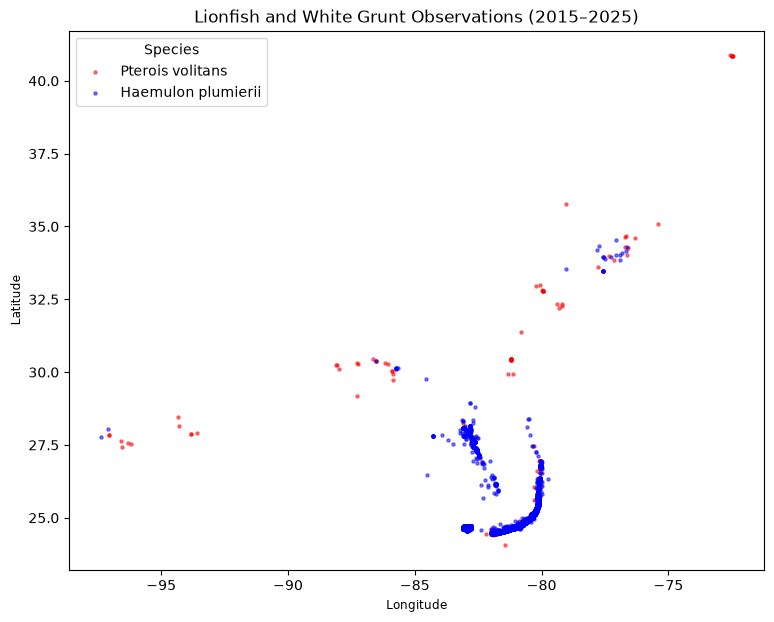

In [7]:
fig, ax = plt.subplots(figsize=(11, 7))

colors = {
    "Pterois volitans": "red",
    "Haemulon plumierii": "blue"}

for species_name, color in colors.items():
    fish_points[
        fish_points["queried_species"] == species_name
    ].plot(
        ax=ax,
        color=color,
        markersize=5,
        alpha=0.5,
        label=species_name)

ax.set_title("Lionfish and White Grunt Observations (2015–2025)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Species")

plt.show()


The initial scatterplot confirmed that the downloaded GBIF coordinates were working correctly, but it did not provide enough geographic context. To better interpret the distributions of lionfish and white grunt, I mapped the observations on top of U.S. state boundaries.

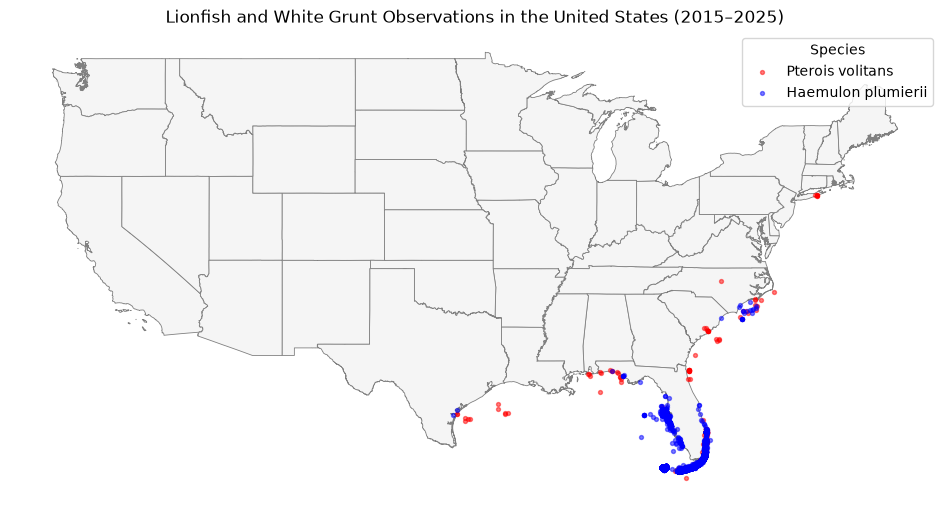

In [8]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_state = "cb_2024_us_state_500k.zip"

states = gpd.read_file(url_0 + url_state)

contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])].copy()

contiguous_us = contiguous_us.to_crs(epsg=4326)
fish_points = fish_points.to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(12, 8))

contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.6)

colors = {
    "Pterois volitans": "red",
    "Haemulon plumierii": "blue"}

for species_name, color in colors.items():
    fish_points[
        fish_points["queried_species"] == species_name
    ].plot(
        ax=ax,
        color=color,
        markersize=8,
        alpha=0.5,
        label=species_name)

ax.set_title("Lionfish and White Grunt Observations in the United States (2015–2025)")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

The initial map shows that many observations are concentrated around Florida and the southeastern coastline. I narrowed the map to this region to better visualize species overlap. Because many fish observations occur offshore, a grid-based approach may be more appropriate than assigning records to state boundaries.

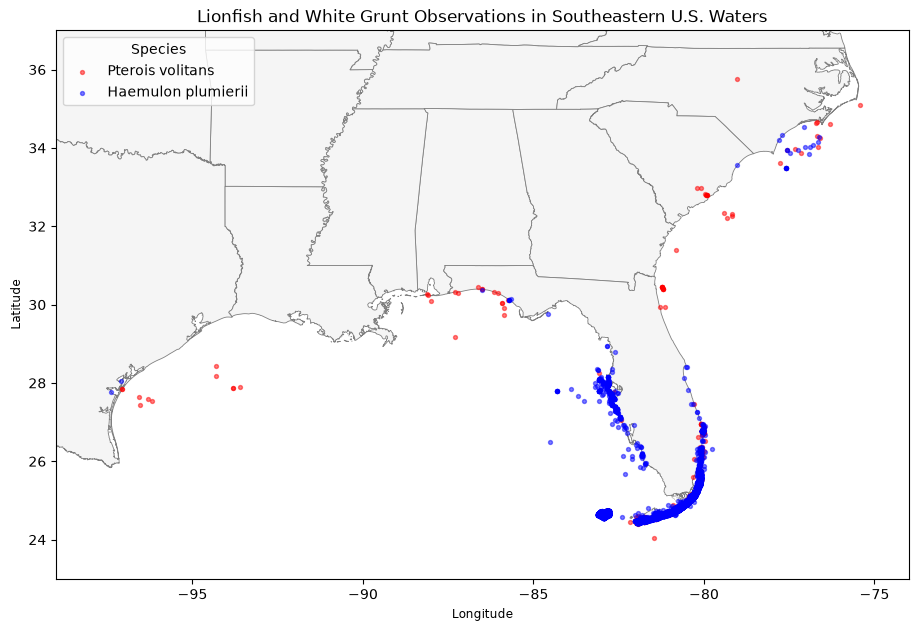

In [9]:
fig, ax = plt.subplots(figsize=(11, 8))

contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.6)

colors = {
    "Pterois volitans": "red",
    "Haemulon plumierii": "blue"}

for species_name, color in colors.items():
    fish_points[
        fish_points["queried_species"] == species_name
    ].plot(
        ax=ax,
        color=color,
        markersize=8,
        alpha=0.5,
        label=species_name)

ax.set_xlim(-99, -74)
ax.set_ylim(23, 37)

ax.set_title("Lionfish and White Grunt Observations in Southeastern U.S. Waters")
ax.legend(title="Species")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

Because many fish observations occur offshore, I created a grid of 100 km × 100 km cells across the southeastern U.S. and surrounding waters. This will allow me to count and compare species observations across consistent geographic areas instead of relying on state boundaries.

Number of grid cells: 405


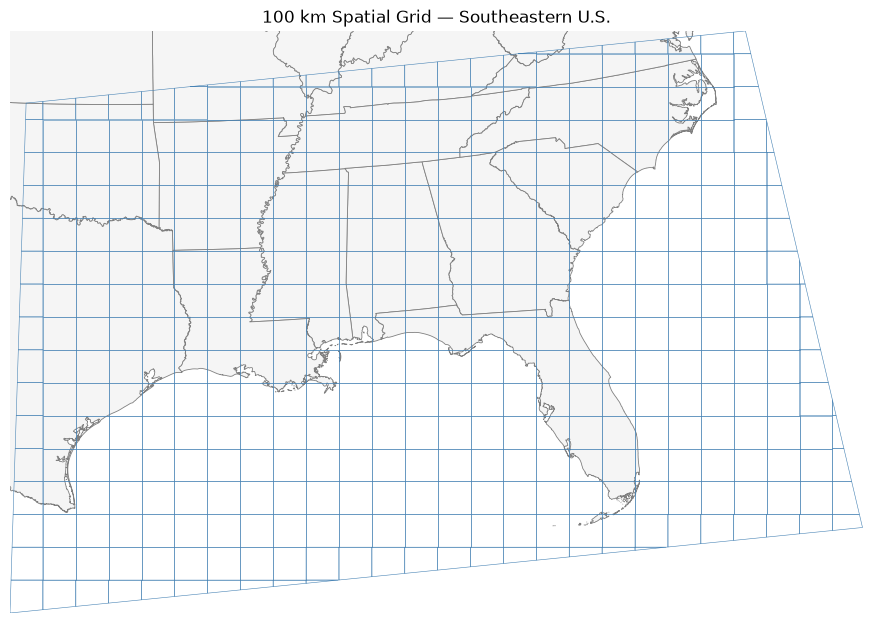

In [10]:
import numpy as np
from shapely.geometry import box

fish_projected = fish_points.to_crs(epsg=5070)

study_area = gpd.GeoSeries(
    [box(-99, 23, -74, 37)],
    crs="EPSG:4326"
).to_crs(epsg=5070)

xmin, ymin, xmax, ymax = study_area.total_bounds

cell_size = 100000
grid_cells = []

for x in np.arange(xmin, xmax, cell_size):
    for y in np.arange(ymin, ymax, cell_size):
        grid_cells.append(
            box(x, y, x + cell_size, y + cell_size))

grid = gpd.GeoDataFrame(
    geometry=grid_cells,
    crs="EPSG:5070")

grid = gpd.clip(grid, study_area)
grid = grid.reset_index(drop=True)
grid["grid_id"] = grid.index

print("Number of grid cells:", len(grid))

fig, ax = plt.subplots(figsize=(11, 8))

contiguous_us.to_crs(epsg=5070).plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.6)

grid.boundary.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.4)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("100 km Spatial Grid — Southeastern U.S.")
ax.set_axis_off()

plt.show()




I used a spatial join to assign each fish observation to a grid cell, then counted the records of each species within each cell. This will allow me to compare their distributions geographically and identify areas with observations of both species.

In [11]:
fish_joined = gpd.sjoin(
    fish_projected,
    grid[["grid_id", "geometry"]],
    how="inner",
    predicate="within")

counts = (fish_joined.groupby(["grid_id", "queried_species"]).size().unstack(fill_value=0))

grid_counts = grid.merge(counts, on="grid_id", how="left")

grid_counts[species] = (grid_counts[species].fillna(0).astype(int))

grid_counts["total"] = grid_counts[species].sum(axis=1)

print("Lionfish:", grid_counts["Pterois volitans"].sum())
print("White grunt:", grid_counts["Haemulon plumierii"].sum())
print("Cells with observations:", (grid_counts["total"] > 0).sum())

grid_counts.head()


Lionfish: 450
White grunt: 9398
Cells with observations: 48


,geometry,grid_id,Haemulon plumierii,Pterois volitans,total
0,"POLYGON ((586616.215 104946.847, 683631.299 10...",0,0,0,0
1,"POLYGON ((486616.215 104946.847, 586616.215 10...",1,0,0,0
2,"POLYGON ((786616.215 204946.847, 886616.215 20...",2,0,0,0
3,"POLYGON ((686616.215 204946.847, 786616.215 20...",3,0,0,0
4,"POLYGON ((486616.215 104946.847, 486616.215 20...",4,0,0,0


Only six lionfish observations weren't assigned to the grid, most likely because they're outside the study boundaries or on cell boundaries.

I created four choropleth maps using total fish observation counts per grid cell. By comparing continuous colors, equal intervals, quantiles, and natural breaks, I can examine how different classification methods influence the appearance and interpretation of species observation patterns. Cells without recorded observations are displayed separately.

Since white grunt accounts for about 95% of my mapped records, the combined choropleths largely reflect white grunt reporting patterns.

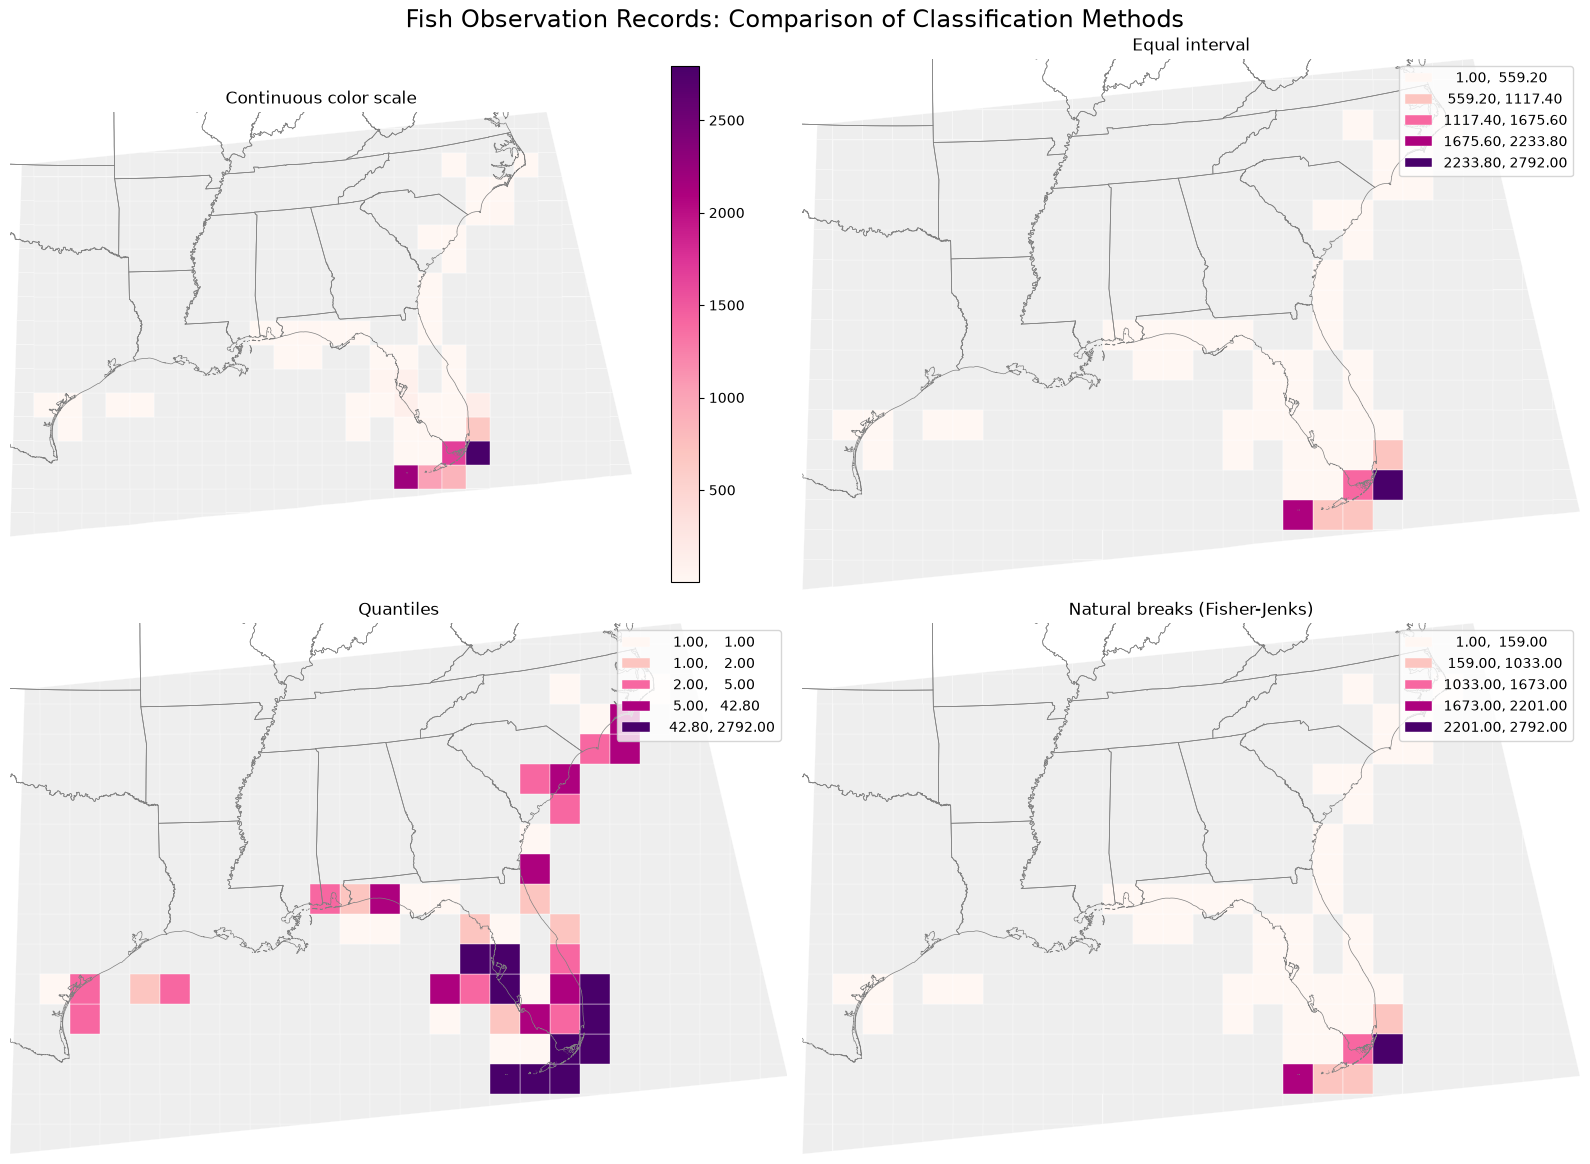

In [12]:
observed = grid_counts[grid_counts["total"] > 0].copy()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

methods = [
    ("Continuous color scale", None),
    ("Equal interval", "equal_interval"),
    ("Quantiles", "quantiles"),
    ("Natural breaks (Fisher-Jenks)", "natural_breaks")]

for ax, (title, scheme) in zip(axes.flat, methods):

    grid_counts.plot(
        ax=ax,
        facecolor="#eeeeee",
        edgecolor="white",
        linewidth=0.2)

    options = {
        "column": "total",
        "cmap": "RdPu",
        "edgecolor": "white",
        "linewidth": 0.3,
        "legend": True,
        "ax": ax}

    if scheme is not None:
        options["scheme"] = scheme
        options["k"] = 5

    observed.plot(**options)

    contiguous_us.to_crs(epsg=5070).boundary.plot(
        ax=ax,
        color="gray",
        linewidth=0.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(title)
    ax.set_axis_off()

plt.suptitle(
    "Fish Observation Records: Comparison of Classification Methods",
    fontsize=17)

plt.tight_layout()

# Save the required PNG
plt.savefig(
    "lionfish_whitegrunt_choropleths.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

I created a bivariate map to compare invasive lionfish and native white grunt observations within the same grid cells. By combining two separate color classifications, the map highlights geographic areas where both species have been recorded and where one species has more observations than the other.

Pterois volitans positive-count median: 3.0
Haemulon plumierii positive-count median: 3.5


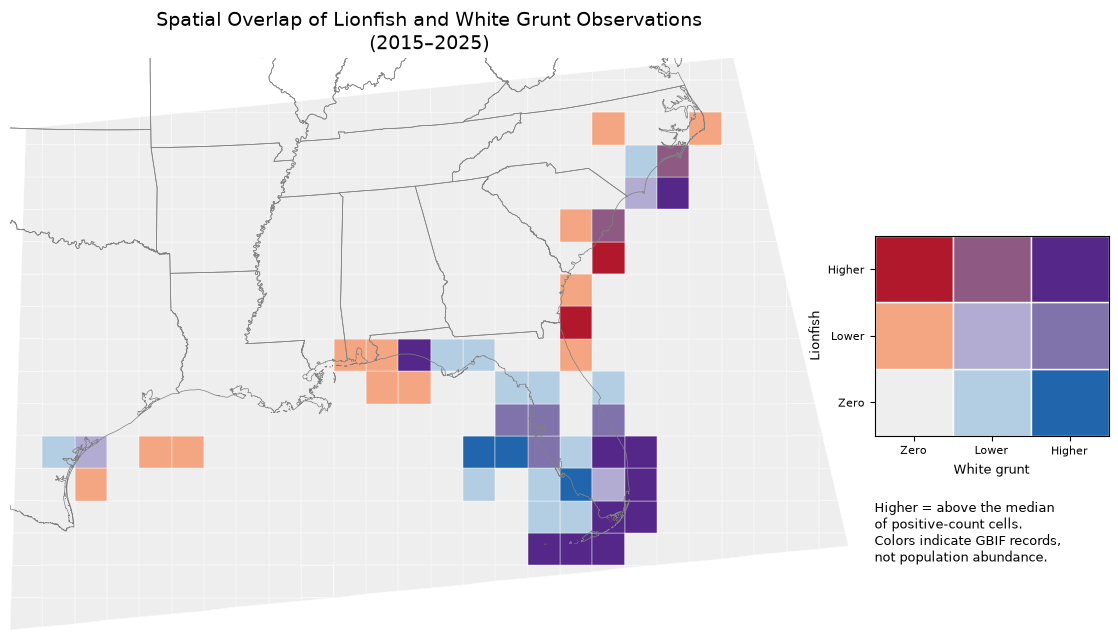

In [14]:
from matplotlib.patches import Rectangle

bivariate = grid_counts.copy()

lionfish = "Pterois volitans"
grunt = "Haemulon plumierii"

for name in [lionfish, grunt]:

    median = bivariate.loc[
        bivariate[name] > 0, name
    ].median()

    bivariate[name + "_class"] = np.select(
        [
            bivariate[name] == 0,
            bivariate[name] <= median
        ],
        [0, 1],
        default=2)

    print(name, "positive-count median:", median)

palette = [
    ["#eeeeee", "#b3cde3", "#2166ac"],
    ["#f4a582", "#b2abd2", "#8073ac"],
    ["#b2182b", "#8e5a83", "#542788"]]

bivariate["color"] = [
    palette[int(l)][int(g)]
    for l, g in zip(
        bivariate[lionfish + "_class"],
        bivariate[grunt + "_class"])]

fig, ax = plt.subplots(figsize=(13, 8))

fig.subplots_adjust(right=0.77)

bivariate.plot(
    ax=ax,
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.3)

contiguous_us.to_crs(epsg=5070).boundary.plot(
    ax=ax,
    color="gray",
    linewidth=0.5)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()

ax.set_title(
    "Spatial Overlap of Lionfish and White Grunt Observations\n(2015–2025)",
    fontsize=14)

legend_ax = fig.add_axes([0.79, 0.38, 0.18, 0.25])

for row in range(3):
    for col in range(3):
        legend_ax.add_patch(
            Rectangle(
                (col, row), 1, 1,
                facecolor=palette[row][col],
                edgecolor="white"))

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("White grunt", fontsize=9)
legend_ax.set_ylabel("Lionfish", fontsize=9)

fig.text(
    0.79, 0.30,
    "Higher = above the median\n"
    "of positive-count cells.\n"
    "Colors indicate GBIF records,\n"
    "not population abundance.",
    fontsize=9,
    va="top")

plt.savefig(
    "lionfish_whitegrunt_bivariate.png",
    dpi=300,
    bbox_inches="tight")

plt.show()


# **Discussion: Classification Methods and Species Distribution**

Comparing the four choropleth maps showed how different classification schemes can change the way species observations are interpreted, even when using the exact same dataset.

- **Continuous color scale:** Emphasized the extremely high concentration of observations around southern Florida, but made lower-count regions difficult to distinguish.

- **Equal interval:** Used consistent numerical ranges, but most grid cells fell into the lowest category because a few cells contained substantially more observations.

- **Quantiles:** Made geographic patterns along the Atlantic and Gulf coasts more visible by distributing cells across classes, but sometimes exaggerated differences between areas with relatively few records.

- **Natural breaks:** Highlighted major concentrations by grouping similar observation counts, but obscured some smaller geographic patterns.

## Bivariate Map Findings

The bivariate map provided a more detailed comparison of the two species. White grunt observations were especially concentrated around southern Florida, while invasive lionfish records were more geographically scattered along the southeastern Atlantic and Gulf coasts. Several grid cells contained observations of both species, particularly around Florida and portions of the Carolina coastline.

These areas of overlap are interesting because lionfish are invasive predators that can affect native reef fish communities. However, geographic overlap alone does not demonstrate direct ecological interactions or predation.

## Limitations and Conclusion

One major limitation is that GBIF occurrence records do not directly measure population abundance. Differences in observation counts may reflect sampling effort, accessibility, or reporting practices rather than actual species distributions. Additionally, using 100 km grid cells can conceal smaller-scale habitat differences, and areas without records should not automatically be interpreted as areas where a species is absent.

Because the choropleth maps use combined observations, their patterns are strongly influenced by the much larger number of white grunt records. The bivariate map addresses this by classifying each species separately, allowing their geographic patterns to be compared more directly. However, these classifications are relative to each species' own recorded observations, so higher classifications do not necessarily indicate higher population abundance or greater ecological impact.

Overall, this analysis demonstrates that classification methods influence which geographic patterns become most visible. While quantiles better revealed the broader distribution of recorded observations, continuous colors and natural breaks emphasized major concentrations. The bivariate map added ecological context by identifying areas of potential spatial overlap between invasive lionfish and native white grunt.

